In [1]:
import sys
import os
sys.path.append(os.path.abspath('../../../'))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from functions.preproc import *
from functions.ucphm import *
from functions.new_variables import *
from functions.ensembles import *
from scipy.stats import skew, shapiro

In [2]:
# Configure pandas display options to show all columns and rows
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)
pd.set_option('display.max_colwidth', None)

In [3]:
dataset = pd.read_excel('../../../BreastCareCond.xlsx')
data_code = pd.read_excel('../../../Codificação variaveis.xlsx')

In [4]:
#Defining the proposed has good treatment variables to use (the empty ones were removed)
relevant_variables = ['PERSON_ID', 'Regional LN recurrence', 'Date of 1st regional recurrence', 'EBC', 'Survival days']
numerical_variables = ['Age', 'Ki67 positive cells (%) at CB']
categorical_variables = ['Grade at CB', 'Side location of the lesion', 
                         'Type of invasion at CB', 'Isotype at CB', 
                         'Oestrogen receptor status at CB', 'Progesterone receptor status at CB', 
                         'Her2 overexpression (with immunohystochemistry) at CB', 
                         'N (Regional nodes affected)']
                         
date_columns = ['Date of CB ', 'Date of 1st breast operation', 'Date of intervention on sentinel lymph node',
                'Date of intervention (axilla)']

In [5]:
#correcting th error in the column name
dataset.rename(columns={'Istotype at CB': 'Isotype at CB'}, inplace=True)

In [6]:
dataset = date_of_diagnosis(dataset, date_columns)

relevant_dates = ['Date of diagnosis', 'Date of 1st regional recurrence']
dataset = remove_zeros_na(dataset, relevant_dates)
dataset = format_date(dataset, relevant_dates)

dataset = survival_days(dataset, ['Date of diagnosis'], ['Date of 1st regional recurrence'])
dataset = tte_negative_patients(dataset)
dataset = filter_EBC(dataset)
dataset.reset_index(drop=True, inplace=True)

In [7]:
survival_dataset = dataset.copy()

Total rows: 3231
Non-missing Ki67: 2693
Missing Ki67: 538


,Ki67
count,2693.000000
mean,31.672856
std,22.552685
min,0.000000
25%,15.000000
50%,25.000000
75%,40.000000
max,100.000000


Skewness: 0.991
Shapiro-Wilk p-value: 0.000000
Median: 25.00
Mean: 31.67
Mode: 20.00


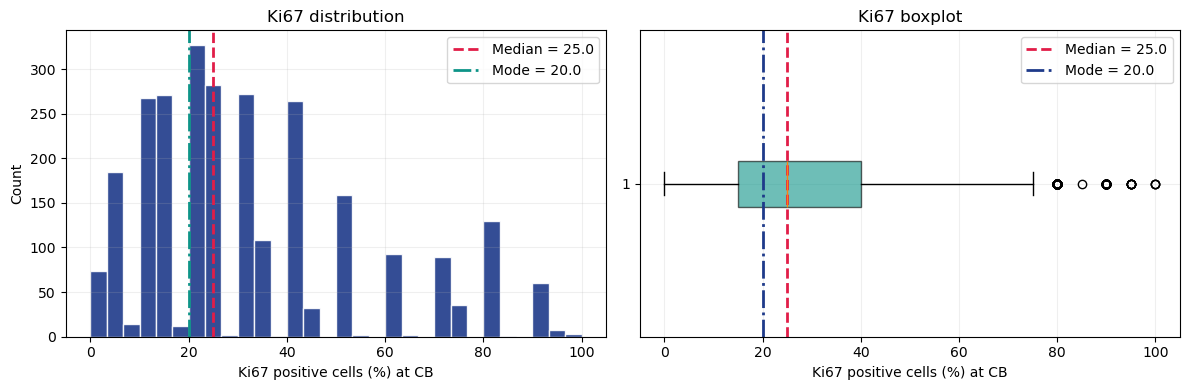

In [8]:
ki67_col = 'Ki67 positive cells (%) at CB'

ki67 = pd.to_numeric(dataset[ki67_col], errors='coerce')
ki67_non_null = ki67.dropna()

print(f"Total rows: {len(dataset)}")
print(f"Non-missing Ki67: {ki67_non_null.shape[0]}")
print(f"Missing Ki67: {ki67.isna().sum()}")

summary = ki67_non_null.describe(percentiles=[0.25, 0.5, 0.75]).to_frame('Ki67')
display(summary)

if ki67_non_null.shape[0] >= 3:
    print(f"Skewness: {skew(ki67_non_null):.3f}")
    shapiro_stat, shapiro_p = shapiro(ki67_non_null.sample(min(5000, len(ki67_non_null)), random_state=42))
    print(f"Shapiro-Wilk p-value: {shapiro_p:.6f}")

# Median and mode
median_val = ki67_non_null.median()
mean_val = ki67_non_null.mean()
mode_vals = ki67_non_null.mode().sort_values()
mode_val = mode_vals.iloc[0] if not mode_vals.empty else np.nan

print(f"Median: {median_val:.2f}")
print(f"Mean: {mean_val:.2f}")
print(f"Mode: {mode_val:.2f}")
if len(mode_vals) > 1:
    print(f"Multiple modes found ({len(mode_vals)}). Displaying first mode in graph: {mode_val:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Histogram
axes[0].hist(ki67_non_null, bins=30, color='#1E3A8A', edgecolor='white', alpha=0.9)
axes[0].axvline(median_val, color='#E11D48', linestyle='--', linewidth=2, label=f"Median = {median_val:.1f}")
axes[0].axvline(mode_val, color='#0D9488', linestyle='-.', linewidth=2, label=f"Mode = {mode_val:.1f}")
axes[0].set_title('Ki67 distribution')
axes[0].set_xlabel('Ki67 positive cells (%) at CB')
axes[0].set_ylabel('Count')
axes[0].grid(alpha=0.2)
axes[0].legend()

# Boxplot
axes[1].boxplot(ki67_non_null, vert=False, patch_artist=True, boxprops=dict(facecolor='#0D9488', alpha=0.6))
axes[1].axvline(median_val, color='#E11D48', linestyle='--', linewidth=2, label=f"Median = {median_val:.1f}")
axes[1].axvline(mode_val, color='#1E3A8A', linestyle='-.', linewidth=2, label=f"Mode = {mode_val:.1f}")
axes[1].set_title('Ki67 boxplot')
axes[1].set_xlabel('Ki67 positive cells (%) at CB')
axes[1].grid(alpha=0.2)
axes[1].legend()

plt.tight_layout()
plt.show()

In [9]:
all_variables = numerical_variables + categorical_variables

In [10]:
treatment_variables = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 
                       'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                         'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
                        'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs', 'Neoadjuvant (bio) therapy only']


In [11]:
mode_variables = all_variables.copy()

In [12]:
mode_variables = ['Grade at CB', 'Side location of the lesion', 'N (Regional nodes affected)', 'Isotype at CB', 'Type of invasion at CB', 'Ki67 positive cells (%) at CB']
handle_missing = ['Progesterone receptor status at CB', 'Oestrogen receptor status at CB', 'Her2 overexpression (with immunohystochemistry) at CB']

In [13]:
vars_in_dataset = [col for col in mode_variables if col in dataset.columns]
vars_not_in_dataset = [col for col in mode_variables if col not in dataset.columns]

missingness_table = (
    dataset[vars_in_dataset]
    .isna()
    .sum()
    .rename('missing_count')
    .to_frame()
)

missingness_table['missing_percent'] = (
    100 * missingness_table['missing_count'] / len(dataset)
).round(2)

missingness_table = missingness_table.sort_values('missing_count', ascending=False).reset_index()
missingness_table = missingness_table.rename(columns={'index': 'variable'})

print("Variables not found in dataset:", vars_not_in_dataset)
display(missingness_table)

Variables not found in dataset: []


,variable,missing_count,missing_percent
0,Ki67 positive cells (%) at CB,538,16.65
1,Grade at CB,195,6.04
2,Isotype at CB,143,4.43
3,Type of invasion at CB,142,4.39
4,Side location of the lesion,14,0.43
5,N (Regional nodes affected),13,0.40


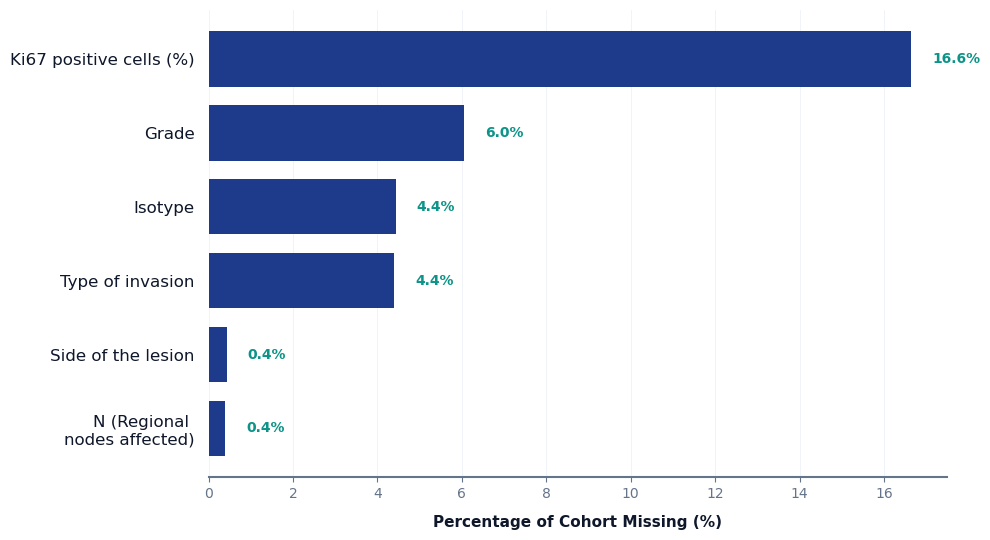

In [14]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare and Rename Data
plot_table = missingness_table.copy()

# --- NEW: The Translation Dictionary ---
# Change the text on the right side of the colon to whatever you want to appear on the slide.
name_mapping = {
    'Grade at CB': 'Grade',
    'Isotype at CB': 'Isotype',
    'Type of invasion at CB': 'Type of invasion',
    'Side location of the lesion': 'Side of the lesion',
    'Classification with respect to other lesions': 'Classification with\nrespect to other lesions',
    'N (Regional nodes affected)': 'N (Regional \nnodes affected)',
    'Disease extent': 'Disease extent',
    'Isotype at CB': 'Isotype',
    'Ki67 positive cells (%) at CB': 'Ki67 positive cells (%)'
}

# Apply the clean names to the dataframe
plot_table['variable'] = plot_table['variable'].replace(name_mapping)

# Sort so the highest missing percentage is at the top
plot_table = plot_table.sort_values('missing_percent', ascending=True) 

# 2. Theme Colors (Clinical Precision)
NAVY = '#1E3A8A'
TEAL = '#0D9488'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'

plt.rcParams.update({
    'font.family': 'sans-serif', 
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': SLATE,
})

# 3. Create transparent figure
# --- NEW: Reduced height from 6.5 to 5.5 to bring the whole chart tighter together ---
fig, ax = plt.subplots(figsize=(10, 5.5), facecolor='none')
ax.set_facecolor('none')

# 4. Plot bars
# --- NEW: Increased height from 0.55 to 0.75. 
# This makes the bars thicker, significantly reducing the gap between them.
bars = ax.barh(plot_table['variable'], plot_table['missing_percent'], 
               color=NAVY, height=0.75, edgecolor='none')

# 5. Clean Titles and Labels
ax.set_xlabel('Percentage of Cohort Missing (%)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('') 

# 6. Remove borders (Spines)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) 
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['bottom'].set_color(MUTED)

# 7. Add a subtle grid
ax.grid(axis='x', color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True) 

# 8. Clean up ticks
ax.tick_params(axis='y', length=0, labelsize=10, pad=10) 
ax.tick_params(axis='x', labelsize=10, color=MUTED)

# 9. Add Percentage Labels
for bar in bars:
    width = bar.get_width()
    if width > 0.1: 
        ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
                va='center', fontsize=10, fontweight='bold', color=TEAL)

ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()

# 10. Export with Transparency
plt.savefig('mode_imputation.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('mode_imputation.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

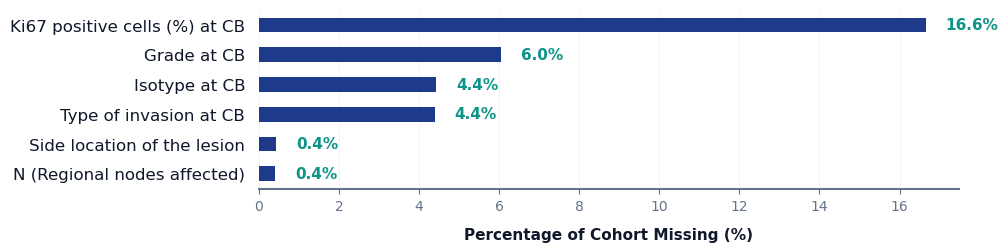

In [15]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare and Rename Data
plot_table = missingness_table.copy()

name_mapping = {
    'Oestrogen receptor status at CB': 'ER status',
    'Her2 overexpression (with immunohystochemistry) at CB': 'HER2 status',
    'Progesterone receptor status at CB': 'PR status'
}

plot_table['variable'] = plot_table['variable'].replace(name_mapping)
plot_table = plot_table.sort_values('missing_percent', ascending=True) 

# 2. Theme Colors
NAVY = '#1E3A8A'
TEAL = '#0D9488'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'

plt.rcParams.update({
    'font.family': 'sans-serif', 
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': SLATE,
})

# 3. Create figure with a much smaller height
# Changed figsize from (10, 5.5) to (10, 3) to prevent stretching
fig, ax = plt.subplots(figsize=(10, 3), facecolor='none')
ax.set_facecolor('none')

# 4. Plot bars
# Height set to 0.8 (closer to 1.0 means bars touch; 0.8 is the "sweet spot" for 3 items)
bars = ax.barh(plot_table['variable'], plot_table['missing_percent'], 
               color=NAVY, height=0.5, edgecolor='none')

# 5. Clean Titles and Labels
ax.set_xlabel('Percentage of Cohort Missing (%)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('') 

# 6. Remove borders (Spines)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) 
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['bottom'].set_color(MUTED)

# 7. Add a subtle grid
ax.grid(axis='x', color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True) 

# 8. Clean up ticks
ax.tick_params(axis='y', length=0, labelsize=12, pad=10) 
ax.tick_params(axis='x', labelsize=10, color=MUTED)

# 9. Add Percentage Labels
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
            va='center', fontsize=11, fontweight='bold', color=TEAL)

# 10. Fine-tune the margins
# This ensures the bars don't "float" too far from the axis labels
plt.subplots_adjust(left=0.2, right=0.9, top=0.9, bottom=0.3)

# 11. Export
plt.savefig('missing_indicator.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('missing_indicator.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

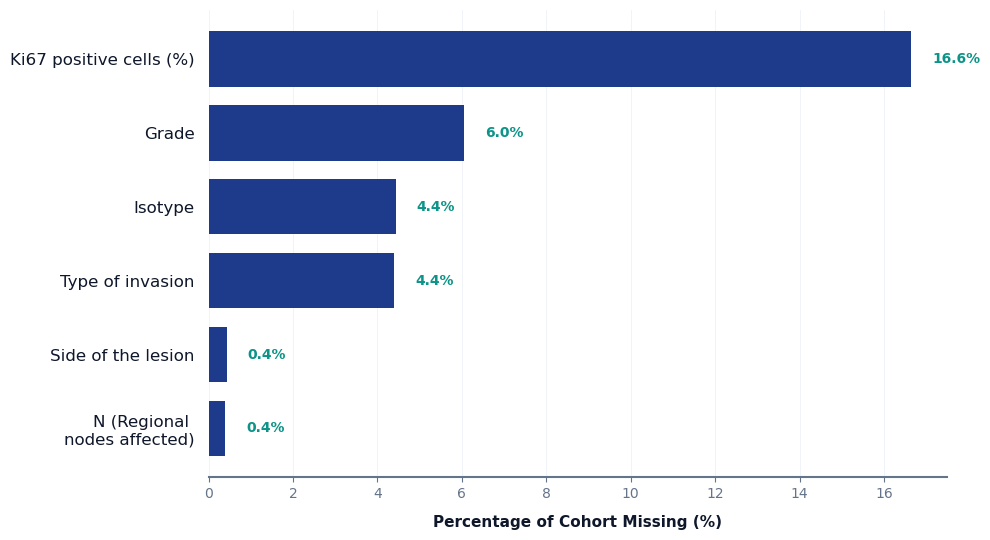

In [16]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare and Rename Data
plot_table = missingness_table.copy()

# --- NEW: The Translation Dictionary ---
# Change the text on the right side of the colon to whatever you want to appear on the slide.
name_mapping = {
    'Grade at CB': 'Grade',
    'Isotype at CB': 'Isotype',
    'Type of invasion at CB': 'Type of invasion',
    'Side location of the lesion': 'Side of the lesion',
    'Classification with respect to other lesions': 'Classification with\nrespect to other lesions',
    'N (Regional nodes affected)': 'N (Regional \nnodes affected)',
    'Disease extent': 'Disease extent',
    'Isotype at CB': 'Isotype',
    'Ki67 positive cells (%) at CB': 'Ki67 positive cells (%)',    
    'Oestrogen receptor status at CB': 'ER status',
    'Her2 overexpression (with immunohystochemistry) at CB': 'HER2 status',
    'Progesterone receptor status at CB': 'PR status'
}

# Apply the clean names to the dataframe
plot_table['variable'] = plot_table['variable'].replace(name_mapping)

# Sort so the highest missing percentage is at the top
plot_table = plot_table.sort_values('missing_percent', ascending=True) 

# 2. Theme Colors (Clinical Precision)
NAVY = '#1E3A8A'
TEAL = '#0D9488'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'

plt.rcParams.update({
    'font.family': 'sans-serif', 
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': SLATE,
})

# 3. Create transparent figure
# --- NEW: Reduced height from 6.5 to 5.5 to bring the whole chart tighter together ---
fig, ax = plt.subplots(figsize=(10, 5.5), facecolor='none')
ax.set_facecolor('none')

# 4. Plot bars
# --- NEW: Increased height from 0.55 to 0.75. 
# This makes the bars thicker, significantly reducing the gap between them.
bars = ax.barh(plot_table['variable'], plot_table['missing_percent'], 
               color=NAVY, height=0.75, edgecolor='none')

# 5. Clean Titles and Labels
ax.set_xlabel('Percentage of Cohort Missing (%)', fontsize=11, fontweight='bold', labelpad=10)
ax.set_ylabel('') 

# 6. Remove borders (Spines)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) 
ax.spines['bottom'].set_linewidth(1.5)
ax.spines['bottom'].set_color(MUTED)

# 7. Add a subtle grid
ax.grid(axis='x', color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax.set_axisbelow(True) 

# 8. Clean up ticks
ax.tick_params(axis='y', length=0, labelsize=10, pad=10) 
ax.tick_params(axis='x', labelsize=10, color=MUTED)

# 9. Add Percentage Labels
for bar in bars:
    width = bar.get_width()
    if width > 0.1: 
        ax.text(width + 0.5, bar.get_y() + bar.get_height()/2, f'{width:.1f}%', 
                va='center', fontsize=10, fontweight='bold', color=TEAL)

ax.tick_params(axis='y', labelsize=12)

plt.tight_layout()

# 10. Export with Transparency
plt.savefig('mode_imputation.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('mode_imputation.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

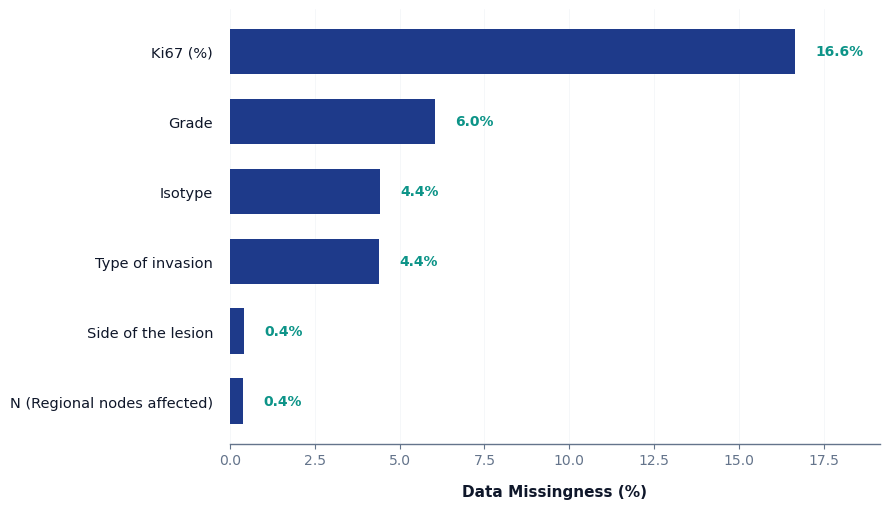

In [17]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare and Rename Data
plot_table = missingness_table.copy()

name_mapping = {
    'Grade at CB': 'Grade',
    'Isotype at CB': 'Isotype',
    'Type of invasion at CB': 'Type of invasion',
    'Side location of the lesion': 'Side of the lesion',
    'Classification with respect to other lesions': 'Classification w/\nrespect to other lesions',
    'N (Regional nodes affected)': 'N (Regional nodes affected)',
    'Disease extent': 'Disease extent',
    'Ki67 positive cells (%) at CB': 'Ki67 (%)',
    'Oestrogen receptor status at CB': 'ER status',
    'Her2 overexpression (with immunohystochemistry) at CB': 'HER2 status',
    'Progesterone receptor status at CB': 'PR status'
}

plot_table['variable'] = plot_table['variable'].replace(name_mapping)
plot_table = plot_table.sort_values('missing_percent', ascending=True)

# 2. Theme Colors
NAVY = '#1E3A8A'
TEAL = '#0D9488'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': SLATE,
})

# 3. Create figure optimized for thesis
# Width: 9in (fits single-column in most thesis templates)
# Height: adjusted for better spacing
fig, ax = plt.subplots(figsize=(9, 5.2), facecolor='none')
ax.set_facecolor('none')

# 4. Plot bars with improved spacing
bars = ax.barh(plot_table['variable'], plot_table['missing_percent'],
               color=NAVY, height=0.65, edgecolor='none')

# 5. Clean Titles and Labels
ax.set_xlabel('Data Missingness (%)', fontsize=11, fontweight='bold', labelpad=12)
ax.set_ylabel('')

# 6. Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_linewidth(1)
ax.spines['bottom'].set_color(MUTED)

# 7. Add subtle grid for readability
ax.grid(axis='x', color=GRID_COLOR, linestyle='-', linewidth=0.4, alpha=0.6)
ax.set_axisbelow(True)

# 8. Tick formatting for readability
ax.tick_params(axis='y', length=0, labelsize=10.5, pad=12)
ax.tick_params(axis='x', labelsize=10)

# 9. Add value labels with better positioning
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.6, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
            va='center', fontsize=10, fontweight='bold', color=TEAL)

# Set x-axis limits to accommodate labels
ax.set_xlim(0, plot_table['missing_percent'].max() * 1.15)

plt.tight_layout()

# Export with transparency
plt.savefig('mode_imputation.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('mode_imputation.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

In [18]:
treatment_variables = ['Radiotherapy (RT) performed', 'Conventional RT fraction', 'Total administered dose', 'Boost dose administered', 
                       'Radiotherapy on chest wall', 'Radiotherapy on supraclavicular area', 'Radiotherapy on internal mammary chain',
                         'State (if hormone therapy prescribed)', 'Treatment in association with chemotherapy', 
                        'Chemotherapy performed', 'Adjuvant chemotherapy', 'Adjuvant therapy with biological drugs', 'Endocrine therapy performed']


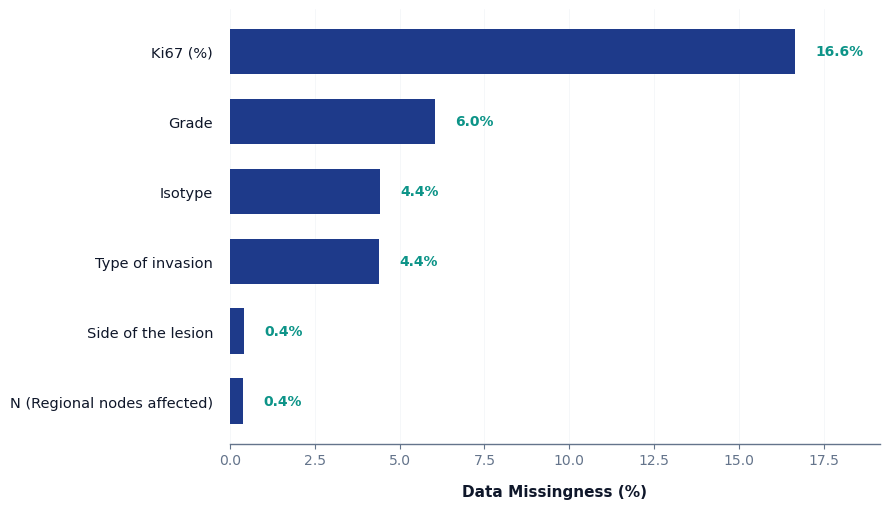

In [19]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Prepare and Rename Data
plot_table = missingness_table.copy()

name_mapping = {
    'Grade at CB': 'Grade',
    'Isotype at CB': 'Isotype',
    'Type of invasion at CB': 'Type of invasion',
    'Side location of the lesion': 'Side of the lesion',
    'Classification with respect to other lesions': 'Classification w/\nrespect to other lesions',
    'N (Regional nodes affected)': 'N (Regional nodes affected)',
    'Disease extent': 'Disease extent',
    'Ki67 positive cells (%) at CB': 'Ki67 (%)',
    'Oestrogen receptor status at CB': 'ER status',
    'Her2 overexpression (with immunohystochemistry) at CB': 'HER2 status',
    'Progesterone receptor status at CB': 'PR status'
}

plot_table['variable'] = plot_table['variable'].replace(name_mapping)
plot_table = plot_table.sort_values('missing_percent', ascending=True)

# 2. Theme Colors
NAVY = '#1E3A8A'
TEAL = '#0D9488'
SLATE = '#0F172A'
MUTED = '#64748B'
GRID_COLOR = '#E2E8F0'

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': SLATE,
})

# 3. Create figure optimized for thesis
# Width: 9in (fits single-column in most thesis templates)
# Height: adjusted for better spacing
fig, ax = plt.subplots(figsize=(9, 5.2), facecolor='none')
ax.set_facecolor('none')

# 4. Plot bars with improved spacing
bars = ax.barh(plot_table['variable'], plot_table['missing_percent'],
               color=NAVY, height=0.65, edgecolor='none')

# 5. Clean Titles and Labels
ax.set_xlabel('Data Missingness (%)', fontsize=11, fontweight='bold', labelpad=12)
ax.set_ylabel('')

# 6. Remove unnecessary borders
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_linewidth(1)
ax.spines['bottom'].set_color(MUTED)

# 7. Add subtle grid for readability
ax.grid(axis='x', color=GRID_COLOR, linestyle='-', linewidth=0.4, alpha=0.6)
ax.set_axisbelow(True)

# 8. Tick formatting for readability
ax.tick_params(axis='y', length=0, labelsize=10.5, pad=12)
ax.tick_params(axis='x', labelsize=10)

# 9. Add value labels with better positioning
for bar in bars:
    width = bar.get_width()
    ax.text(width + 0.6, bar.get_y() + bar.get_height()/2, f'{width:.1f}%',
            va='center', fontsize=10, fontweight='bold', color=TEAL)

# Set x-axis limits to accommodate labels
ax.set_xlim(0, plot_table['missing_percent'].max() * 1.15)

plt.tight_layout()

# Export with transparency
plt.savefig('mode_imputation.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('mode_imputation.pdf', dpi=300, transparent=True, bbox_inches='tight')
plt.show()

## Side location

In [20]:
side_col = 'Side location of the lesion'
recurrence_col = 'Regional LN recurrence'

side_df = dataset[[side_col, recurrence_col]].copy()
side_df = side_df.dropna(subset=[side_col])
side_df[side_col] = side_df[side_col].astype(str)

print('=== Side location distribution (all patients) ===')
side_counts = side_df[side_col].value_counts().rename_axis(side_col).to_frame('count')
side_counts['percentage'] = (100 * side_counts['count'] / side_counts['count'].sum()).round(2)
display(side_counts)

print('\n=== Side location distribution by recurrence status ===')
side_by_recurrence = pd.crosstab(side_df[side_col], side_df[recurrence_col])
side_by_recurrence = side_by_recurrence.rename(columns={0: 'No recurrence (0)', 1: 'Recurrence (1)'})
side_by_recurrence['Total'] = side_by_recurrence.sum(axis=1)
display(side_by_recurrence)

print('\n=== Recurrence rate by side location ===')
if 'Recurrence (1)' in side_by_recurrence.columns:
    recurrence_rate = (
        100 * side_by_recurrence['Recurrence (1)'] / side_by_recurrence['Total']
    ).round(2).to_frame('recurrence_rate_percent')
    display(recurrence_rate)
else:
    print('No patients with recurrence = 1 in the current filtered data.')

=== Side location distribution (all patients) ===


,count,percentage
Side location of the lesion,,
L,1676,52.1
R,1541,47.9



=== Side location distribution by recurrence status ===


Regional LN recurrence,No recurrence (0),Recurrence (1),Total
Side location of the lesion,,,
L,1652,24,1676
R,1529,12,1541



=== Recurrence rate by side location ===


,recurrence_rate_percent
Side location of the lesion,
L,1.43
R,0.78


In [21]:
dose_variables = ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']
recurrence_col = 'Regional LN recurrence'

num_df = dataset[dose_variables + [recurrence_col]].copy()
for col in dose_variables:
    num_df[col] = pd.to_numeric(num_df[col], errors='coerce')

print('=== Dose variables distribution (all patients) ===')
overall_summary = num_df[dose_variables].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
display(overall_summary.round(3))

print('\n=== Dose variables distribution by recurrence status ===')
for col in dose_variables:
    print(f'\n--- {col} ---')
    split_summary = (
        num_df.groupby(recurrence_col)[col]
        .describe()[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
        .rename(index={0: 'No recurrence (0)', 1: 'Recurrence (1)'})
    )
    display(split_summary.round(3))

print('\n=== Missing values (dose variables) ===')
missing_table = num_df[dose_variables].isna().sum().to_frame('missing_count')
missing_table['missing_percent'] = (100 * missing_table['missing_count'] / len(num_df)).round(2)
display(missing_table)

=== Dose variables distribution (all patients) ===


,count,mean,std,min,25%,50%,75%,max
Conventional RT fraction,2592.0,3.099,1.159,2.0,3.0,3.0,3.0,24.0
Total administered dose,2614.0,40.986,4.167,5.0,41.0,41.0,41.0,70.0
Boost dose administered,2320.0,2.971,0.569,2.0,3.0,3.0,3.0,24.0



=== Dose variables distribution by recurrence status ===

--- Conventional RT fraction ---


,count,mean,std,min,25%,50%,75%,max
Regional LN recurrence,,,,,,,,
No recurrence (0),2574.0,3.099,1.160,2.0,3.0,3.0,3.0,24.0
Recurrence (1),18.0,3.056,1.056,2.0,3.0,3.0,3.0,7.0



--- Total administered dose ---


,count,mean,std,min,25%,50%,75%,max
Regional LN recurrence,,,,,,,,
No recurrence (0),2595.0,40.986,4.150,5.0,41.0,41.0,41.0,70.0
Recurrence (1),19.0,41.053,6.142,21.0,41.0,41.0,41.0,50.0



--- Boost dose administered ---


,count,mean,std,min,25%,50%,75%,max
Regional LN recurrence,,,,,,,,
No recurrence (0),2304.0,2.972,0.570,2.0,3.0,3.0,3.0,24.0
Recurrence (1),16.0,2.812,0.403,2.0,3.0,3.0,3.0,3.0



=== Missing values (dose variables) ===


,missing_count,missing_percent
Conventional RT fraction,639,19.78
Total administered dose,617,19.10
Boost dose administered,911,28.20


In [22]:
from scipy import stats

side_col = 'Side location of the lesion'
dose_variables = ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']

lr_df = dataset[[side_col] + dose_variables].copy()
lr_df = lr_df.dropna(subset=[side_col]).copy()
lr_df[side_col] = lr_df[side_col].astype(str).str.upper().str.strip()
lr_df = lr_df[lr_df[side_col].isin(['L', 'R'])]

for col in dose_variables:
    lr_df[col] = pd.to_numeric(lr_df[col], errors='coerce')

print('=== Left vs Right dose statistics ===')
for col in dose_variables:
    print(f'\n--- {col} ---')
    analysis_df = lr_df[[side_col, col]].dropna()

    left = analysis_df.loc[analysis_df[side_col] == 'L', col]
    right = analysis_df.loc[analysis_df[side_col] == 'R', col]

    summary = analysis_df.groupby(side_col)[col].agg(['count', 'mean', 'std', 'median', 'min', 'max']).round(3)
    display(summary)

    if len(left) >= 3 and len(right) >= 3:
        mw_stat, mw_p = stats.mannwhitneyu(left, right, alternative='two-sided')
        t_stat, t_p = stats.ttest_ind(left, right, equal_var=False, nan_policy='omit')

        test_table = pd.DataFrame({
            'test': ['Mann-Whitney U', "Welch's t-test"],
            'statistic': [mw_stat, t_stat],
            'p_value': [mw_p, t_p]
        })
        display(test_table.round(6))

        print(
            f"mean(L)-mean(R) = {(left.mean() - right.mean()):.3f} | "
            f"median(L)-median(R) = {(left.median() - right.median()):.3f}"
        )
    else:
        print('Not enough observations in one of the groups to run statistical tests (need at least 3 per group).')

=== Left vs Right dose statistics ===

--- Conventional RT fraction ---


,count,mean,std,median,min,max
Side location of the lesion,,,,,,
L,1337,3.075,1.160,3.0,2.0,24.0
R,1242,3.126,1.163,3.0,2.0,24.0


,test,statistic,p_value
0,Mann-Whitney U,788165.500000,0.000073
1,Welch's t-test,-1.127318,0.259714


mean(L)-mean(R) = -0.052 | median(L)-median(R) = 0.000

--- Total administered dose ---


,count,mean,std,median,min,max
Side location of the lesion,,,,,,
L,1349,41.271,4.301,41.0,8.0,70.0
R,1252,40.680,4.018,41.0,5.0,50.0


,test,statistic,p_value
0,Mann-Whitney U,890893.500000,0.000044
1,Welch's t-test,3.622159,0.000298


mean(L)-mean(R) = 0.591 | median(L)-median(R) = 0.000

--- Boost dose administered ---


,count,mean,std,median,min,max
Side location of the lesion,,,,,,
L,1194,2.950,0.711,3.0,2.0,24.0
R,1113,2.993,0.365,3.0,2.0,7.0


,test,statistic,p_value
0,Mann-Whitney U,631052.00000,0.000003
1,Welch's t-test,-1.84829,0.064724


mean(L)-mean(R) = -0.043 | median(L)-median(R) = 0.000


In [23]:
side_col = 'Side location of the lesion'
dose_variables = ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']

check_df = dataset[[side_col] + dose_variables].copy()
check_df[side_col] = check_df[side_col].astype(str).str.upper().str.strip()
check_df = check_df[check_df[side_col].isin(['L', 'R'])]

for col in dose_variables:
    check_df[col] = pd.to_numeric(check_df[col], errors='coerce')

print('=== Which side usually has higher doses? ===')
comparison_rows = []
for col in dose_variables:
    tmp = check_df[[side_col, col]].dropna()
    mean_l = tmp.loc[tmp[side_col] == 'L', col].mean()
    mean_r = tmp.loc[tmp[side_col] == 'R', col].mean()
    med_l = tmp.loc[tmp[side_col] == 'L', col].median()
    med_r = tmp.loc[tmp[side_col] == 'R', col].median()

    higher_mean = 'L' if mean_l > mean_r else ('R' if mean_r > mean_l else 'Tie')
    higher_median = 'L' if med_l > med_r else ('R' if med_r > med_l else 'Tie')

    comparison_rows.append({
        'variable': col,
        'mean_L': mean_l,
        'mean_R': mean_r,
        'higher_mean_side': higher_mean,
        'median_L': med_l,
        'median_R': med_r,
        'higher_median_side': higher_median,
    })

comparison_table = pd.DataFrame(comparison_rows).round(3)
display(comparison_table)

print('\n=== Number of patients with dose > 0 by side ===')
count_rows = []
for col in dose_variables:
    tmp = check_df[[side_col, col]].dropna()
    l_gt0 = ((tmp[side_col] == 'L') & (tmp[col] > 0)).sum()
    r_gt0 = ((tmp[side_col] == 'R') & (tmp[col] > 0)).sum()

    count_rows.append({
        'variable': col,
        'L_dose_gt_0_count': int(l_gt0),
        'R_dose_gt_0_count': int(r_gt0),
        'total_dose_gt_0_count': int(l_gt0 + r_gt0),
    })

gt0_counts = pd.DataFrame(count_rows)
display(gt0_counts)

print('\n=== Patients with all three doses > 0 (by side) ===')
all_three = check_df.dropna(subset=dose_variables).copy()
all_three['all_three_gt_0'] = (all_three[dose_variables] > 0).all(axis=1)
all_three_counts = (
    all_three[all_three['all_three_gt_0']]
    .groupby(side_col)
    .size()
    .rename('count_all_three_gt_0')
    .to_frame()
)
display(all_three_counts)

=== Which side usually has higher doses? ===


,variable,mean_L,mean_R,higher_mean_side,median_L,median_R,higher_median_side
0,Conventional RT fraction,3.075,3.126,R,3.0,3.0,Tie
1,Total administered dose,41.271,40.680,L,41.0,41.0,Tie
2,Boost dose administered,2.950,2.993,R,3.0,3.0,Tie



=== Number of patients with dose > 0 by side ===


,variable,L_dose_gt_0_count,R_dose_gt_0_count,total_dose_gt_0_count
0,Conventional RT fraction,1337,1242,2579
1,Total administered dose,1349,1252,2601
2,Boost dose administered,1194,1113,2307



=== Patients with all three doses > 0 (by side) ===


,count_all_three_gt_0
Side location of the lesion,
L,1194
R,1113


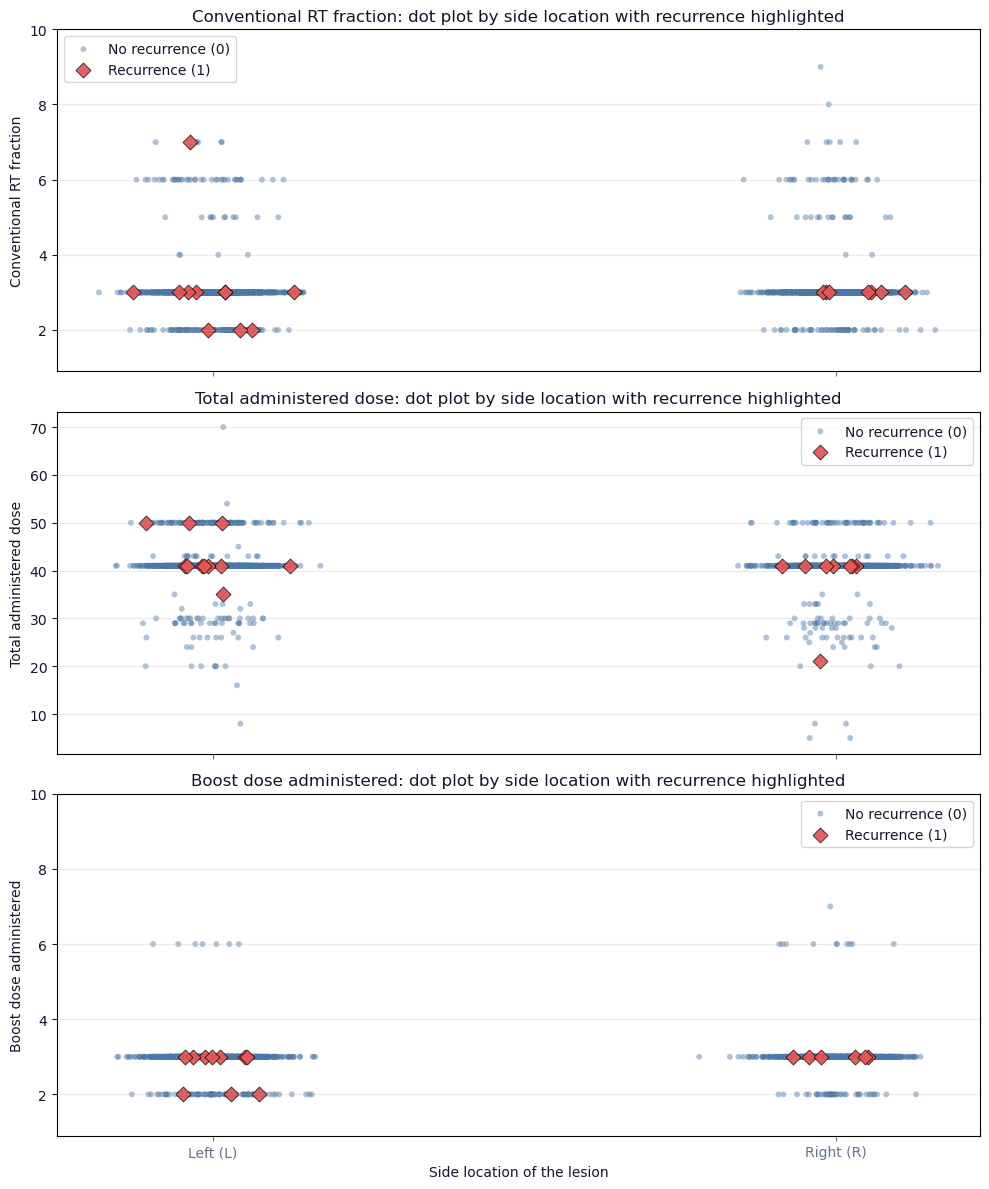

In [24]:
side_col = 'Side location of the lesion'
recurrence_col = 'Regional LN recurrence'
dose_variables = ['Conventional RT fraction', 'Total administered dose', 'Boost dose administered']

plot_df = dataset[[side_col, recurrence_col] + dose_variables].copy()
plot_df[side_col] = plot_df[side_col].astype(str).str.upper().str.strip()
plot_df = plot_df[plot_df[side_col].isin(['L', 'R'])]
plot_df[recurrence_col] = pd.to_numeric(plot_df[recurrence_col], errors='coerce')

for col in dose_variables:
    plot_df[col] = pd.to_numeric(plot_df[col], errors='coerce')

rng = np.random.default_rng(42)
side_to_x = {'L': 0, 'R': 1}

fig, axes = plt.subplots(len(dose_variables), 1, figsize=(10, 4 * len(dose_variables)), sharex=True)

for i, col in enumerate(dose_variables):
    ax = axes[i]
    temp = plot_df[[side_col, recurrence_col, col]].dropna()

    x_base = temp[side_col].map(side_to_x).to_numpy(dtype=float)
    x_jitter = x_base + rng.normal(0, 0.05, size=len(temp))

    rec_mask = temp[recurrence_col].eq(1).to_numpy()

    # Non-recurrence points
    ax.scatter(
        x_jitter[~rec_mask],
        temp.loc[~rec_mask, col],
        s=18,
        alpha=0.45,
        color='#4C78A8',
        edgecolors='none',
        label='No recurrence (0)'
    )

    # Recurrence points highlighted
    ax.scatter(
        x_jitter[rec_mask],
        temp.loc[rec_mask, col],
        s=58,
        alpha=0.95,
        color='#E45756',
        edgecolors='black',
        linewidths=0.5,
        marker='D',
        label='Recurrence (1)'
    )

    ax.set_title(f'{col}: dot plot by side location with recurrence highlighted')
    ax.set_ylabel(col)
    ax.grid(axis='y', alpha=0.25)

    # Cap first and third plots at y=10
    if i in (0, 2):
        ax.set_ylim(top=10)

    handles, labels = ax.get_legend_handles_labels()
    dedup = dict(zip(labels, handles))
    ax.legend(dedup.values(), dedup.keys(), loc='best')

axes[-1].set_xticks([0, 1])
axes[-1].set_xticklabels(['Left (L)', 'Right (R)'])
axes[-1].set_xlabel('Side location of the lesion')

plt.tight_layout()
plt.show()

In [25]:
from scipy.stats import chi2_contingency

side_col = 'Side location of the lesion'
markers = [
    'Oestrogen receptor status at CB',
    'Progesterone receptor status at CB',
    'Her2 overexpression (with immunohystochemistry) at CB',
    'Ki67 positive cells (%) at CB'
]

dist_df = dataset[[side_col] + markers].copy()
dist_df[side_col] = dist_df[side_col].astype(str).str.upper().str.strip()
dist_df = dist_df[dist_df[side_col].isin(['L', 'R'])]

print('=== Receptor distributions by breast side (Left vs Right) ===')

for marker in markers:
    print(f'\n--- {marker} ---')

    tmp = dist_df[[side_col, marker]].copy()
    tmp[marker] = tmp[marker].fillna('Missing').astype(str)

    count_table = pd.crosstab(tmp[side_col], tmp[marker])
    pct_within_side = (pd.crosstab(tmp[side_col], tmp[marker], normalize='index') * 100).round(2)

    print('Counts')
    display(count_table)

    print('Percent within each side (%)')
    display(pct_within_side)

    if count_table.shape[0] > 1 and count_table.shape[1] > 1:
        chi2, p_value, dof, _ = chi2_contingency(count_table)
        print(f'Chi-square p-value: {p_value:.6f} (dof={dof})')
    else:
        print('Chi-square test not applicable (insufficient category variation).')

=== Receptor distributions by breast side (Left vs Right) ===

--- Oestrogen receptor status at CB ---
Counts


Oestrogen receptor status at CB,1.0,2.0,Missing
Side location of the lesion,,,
L,242,1350,84
R,201,1287,53


Percent within each side (%)


Oestrogen receptor status at CB,1.0,2.0,Missing
Side location of the lesion,,,
L,14.44,80.55,5.01
R,13.04,83.52,3.44


Chi-square p-value: 0.035779 (dof=2)

--- Progesterone receptor status at CB ---
Counts


Progesterone receptor status at CB,1.0,2.0,Missing
Side location of the lesion,,,
L,335,1087,254
R,330,1018,193


... (7 outputs left out)

Ki67 positive cells (%) at CB,0.0,1.0,10.0,100.0,12.0,13.0,15.0,16.0,17.0,18.0,2.0,20.0,21.0,22.0,24.0,25.0,26.0,28.0,3.0,30.0,33.0,35.0,39.0,4.0,40.0,45.0,5.0,50.0,55.0,6.0,60.0,65.0,7.0,70.0,74.0,75.0,8.0,80.0,85.0,90.0,95.0,Missing
Side location of the lesion,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
L,0,2,130,1,2,2,150,0,1,4,15,159,0,1,2,152,0,1,20,141,0,49,1,2,129,12,89,85,0,1,52,1,0,49,1,17,6,61,1,33,2,302
R,3,3,131,2,2,0,116,5,1,6,8,162,1,0,0,126,1,1,23,126,1,59,0,2,133,20,88,74,2,2,41,1,3,40,0,17,5,69,0,27,5,235


Percent within each side (%)


Ki67 positive cells (%) at CB,0.0,1.0,10.0,100.0,12.0,13.0,15.0,16.0,17.0,18.0,2.0,20.0,21.0,22.0,24.0,25.0,26.0,28.0,3.0,30.0,33.0,35.0,39.0,4.0,40.0,45.0,5.0,50.0,55.0,6.0,60.0,65.0,7.0,70.0,74.0,75.0,8.0,80.0,85.0,90.0,95.0,Missing
Side location of the lesion,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
L,0.00,0.12,7.76,0.06,0.12,0.12,8.95,0.00,0.06,0.24,0.89,9.49,0.00,0.06,0.12,9.07,0.00,0.06,1.19,8.41,0.00,2.92,0.06,0.12,7.70,0.72,5.31,5.07,0.00,0.06,3.10,0.06,0.00,2.92,0.06,1.01,0.36,3.64,0.06,1.97,0.12,18.02
R,0.19,0.19,8.50,0.13,0.13,0.00,7.53,0.32,0.06,0.39,0.52,10.51,0.06,0.00,0.00,8.18,0.06,0.06,1.49,8.18,0.06,3.83,0.00,0.13,8.63,1.30,5.71,4.80,0.13,0.13,2.66,0.06,0.19,2.60,0.00,1.10,0.32,4.48,0.00,1.75,0.32,15.25


Chi-square p-value: 0.257246 (dof=41)


## Continuing

In [26]:
survival_dataset = dataset

In [27]:
# Find duplicated patients
mask = (survival_dataset.duplicated(subset='PERSON_ID', keep=False) & (survival_dataset['Regional LN recurrence'] == 1))

# For each duplicated PERSON_ID with recurrence, keep only the first row
to_remove = (
    survival_dataset[mask]
    .groupby('PERSON_ID')
    .tail(-1)
    .index
)

survival_dataset = survival_dataset.drop(to_remove)

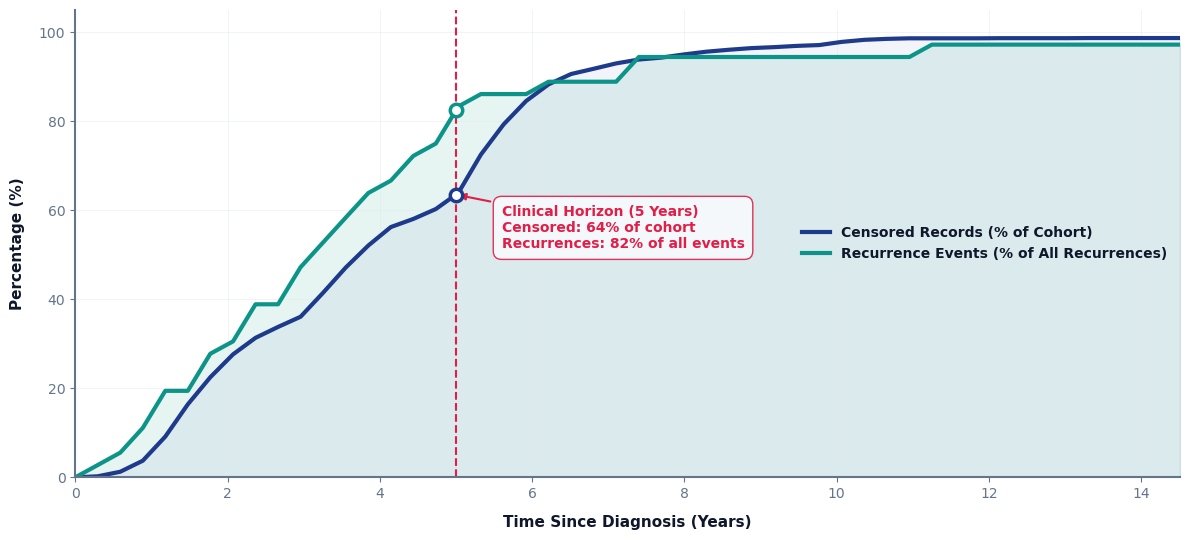

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Your original data processing (Same as before)
time_points = np.linspace(0, 5300, 50).astype(int).tolist()
censoring_analysis = []
total_events = int((survival_dataset['Regional LN recurrence'] == 1).sum())

for t in time_points:
    n_events = int(((survival_dataset['Survival days'] <= t) & 
                    (survival_dataset['Regional LN recurrence'] == 1)).sum())
    
    n_censored = int(((survival_dataset['Survival days'] <= t) & 
                      (survival_dataset['Regional LN recurrence'] == 0)).sum())
    
    n_followup = n_events + n_censored
    n_total = len(survival_dataset)
    
    censoring_analysis.append({
        'time_days': t,
        'time_years': t / 365.25,
        'n_total_patients': n_total,
        'n_events': n_events,
        'n_censored': n_censored,
        'pct_events': (n_events / n_total * 100) if n_total > 0 else 0,
        'pct_censored': (n_censored / n_total * 100) if n_total > 0 else 0,
        'pct_events_of_events': (n_events / total_events * 100) if total_events > 0 else 0,
    })

censoring_df = pd.DataFrame(censoring_analysis)

# 2. AESTHETIC CONFIGURATION
NAVY = '#1E3A8A'       
TEAL = '#0D9488'       
CRIMSON = '#E11D48'    
SLATE = '#0F172A'      
MUTED = '#64748B'      
GRID_COLOR = '#E2E8F0'
BOX_BG = '#F8FAFC' # Kept only for the text box readability

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'axes.edgecolor': MUTED,
})

# REMOVED facecolor to allow transparency
fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax1.set_facecolor('none') # Makes the plot area transparent

x_vals = censoring_df['time_years']

# 3. Plot the clean, thick lines
ax1.plot(x_vals, censoring_df['pct_censored'], color=NAVY, linewidth=3, label='Censored Records (% of Cohort)')
ax1.plot(x_vals, censoring_df['pct_events_of_events'], color=TEAL, linewidth=3, label='Recurrence Events (% of All Recurrences)')

# Add subtle shading under the curves
ax1.fill_between(x_vals, censoring_df['pct_censored'], color=NAVY, alpha=0.05)
ax1.fill_between(x_vals, censoring_df['pct_events_of_events'], color=TEAL, alpha=0.1)

# 4. Highlight the 5-Year Clinical Cutoff
cutoff_year = 5.0
cutoff_day = cutoff_year * 365.25
cutoff_event_pct = np.interp(cutoff_day, censoring_df['time_days'], censoring_df['pct_events_of_events'])
cutoff_cens_pct = np.interp(cutoff_day, censoring_df['time_days'], censoring_df['pct_censored'])

ax1.axvline(cutoff_year, color=CRIMSON, linestyle='--', linewidth=1.5, zorder=2)

# Using 'white' for the hollow points so they punch through the transparent background
ax1.scatter([cutoff_year], [cutoff_event_pct], color='white', edgecolor=TEAL, s=80, linewidth=2.5, zorder=5)
ax1.scatter([cutoff_year], [cutoff_cens_pct], color='white', edgecolor=NAVY, s=80, linewidth=2.5, zorder=5)

# Modern floating annotation box (with 2 decimal places)
bbox_props = dict(boxstyle="round,pad=0.6", fc=BOX_BG, ec=CRIMSON, alpha=0.9, lw=1)
ax1.annotate(
    f"Clinical Horizon (5 Years)\nCensored: {cutoff_cens_pct:.0f}% of cohort\nRecurrences: {cutoff_event_pct:.0f}% of all events",
    xy=(cutoff_year, cutoff_cens_pct),
    xytext=(cutoff_year + 0.6, cutoff_cens_pct - 12),
    arrowprops=dict(arrowstyle="-|>", color=CRIMSON, lw=1.5),
    fontsize=10, fontweight='bold', color=CRIMSON,
    bbox=bbox_props
)

# 5. Final Formatting & Grid
ax1.set_xlabel('Time Since Diagnosis (Years)', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_ylabel('Percentage (%)', fontsize=11, fontweight='bold', labelpad=10)

ax1.grid(color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(1.5)
ax1.spines['bottom'].set_linewidth(1.5)

ax1.set_ylim(0, max(censoring_df['pct_censored'].max(), 100) * 1.05)
ax1.set_xlim(0, max(x_vals))

# Transparent legend
leg = ax1.legend(loc='center right', frameon=False) # Removed the frame for clean integration
for text in leg.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()

# CRITICAL: transparent=True is what actually exports the PNG without a white background
plt.savefig('clinical_censoring_plot_transparent.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('clinical_censoring_plot_transparent.pdf', dpi=300, transparent=True, bbox_inches='tight')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. Your original data processing (Same as before)
time_points = np.linspace(0, 5300, 50).astype(int).tolist()
censoring_analysis = []
total_events = int((survival_dataset['Regional LN recurrence'] == 1).sum())

for t in time_points:
    n_events = int(((survival_dataset['Survival days'] <= t) & 
                    (survival_dataset['Regional LN recurrence'] == 1)).sum())
    
    n_censored = int(((survival_dataset['Survival days'] <= t) & 
                      (survival_dataset['Regional LN recurrence'] == 0)).sum())
    
    n_followup = n_events + n_censored
    n_total = len(survival_dataset)
    
    censoring_analysis.append({
        'time_days': t,
        'time_years': t / 365.25,
        'n_total_patients': n_total,
        'n_events': n_events,
        'n_censored': n_censored,
        'pct_events': (n_events / n_total * 100) if n_total > 0 else 0,
        'pct_censored': (n_censored / n_total * 100) if n_total > 0 else 0,
        'pct_events_of_events': (n_events / total_events * 100) if total_events > 0 else 0,
    })

censoring_df = pd.DataFrame(censoring_analysis)

# 2. AESTHETIC CONFIGURATION
NAVY = '#1E3A8A'       
TEAL = '#0D9488'       
CRIMSON = '#E11D48'    
SLATE = '#0F172A'      
MUTED = '#64748B'      
GRID_COLOR = '#E2E8F0'
BOX_BG = '#F8FAFC' # Kept only for the text box readability

plt.rcParams.update({
    'font.family': 'sans-serif',
    'text.color': SLATE,
    'axes.labelcolor': SLATE,
    'xtick.color': MUTED,
    'ytick.color': MUTED,
    'axes.edgecolor': MUTED,
})

# REMOVED facecolor to allow transparency
fig, ax1 = plt.subplots(figsize=(12, 5.5))
ax1.set_facecolor('none') # Makes the plot area transparent

x_vals = censoring_df['time_years']

# 3. Plot the clean, thick lines
ax1.plot(x_vals, censoring_df['pct_censored'], color=NAVY, linewidth=3, label='Censored Patients (% of Cohort)')
ax1.plot(x_vals, censoring_df['pct_events_of_events'], color=TEAL, linewidth=3, label='Recurrence Events (% of All Recurrences)')

# Add subtle shading under the curves
ax1.fill_between(x_vals, censoring_df['pct_censored'], color=NAVY, alpha=0.05)
ax1.fill_between(x_vals, censoring_df['pct_events_of_events'], color=TEAL, alpha=0.1)

# Remmoved the 5 year anntation for the presentation

# 5. Final Formatting & Grid
ax1.set_xlabel('Time Since Diagnosis (Years)', fontsize=11, fontweight='bold', labelpad=10)
ax1.set_ylabel('Percentage (%)', fontsize=11, fontweight='bold', labelpad=10)

ax1.grid(color=GRID_COLOR, linestyle='-', linewidth=0.5, alpha=0.7)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_linewidth(1.5)
ax1.spines['bottom'].set_linewidth(1.5)

ax1.set_ylim(0, max(censoring_df['pct_censored'].max(), 100) * 1.05)
ax1.set_xlim(0, max(x_vals))

# Transparent legend
leg = ax1.legend(loc='center right', frameon=False) # Removed the frame for clean integration
for text in leg.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()

# CRITICAL: transparent=True is what actually exports the PNG without a white background
plt.savefig('clinical_censoring_plot_transparent.png', dpi=300, transparent=True, bbox_inches='tight')
plt.savefig('clinical_censoring_plot_transparent.pdf', dpi=300, transparent=True, bbox_inches='tight')

NameError: name 'survival_dataset' is not defined